# Session 12: Choosing, checking, and reading statistical tests

**CPBP 8306-02 · November 19, 2026**

In Session 1, a t-test said "no difference" between groups A and B (*p* = 0.2152). After the trailing space in `"A "` was fixed, the same test said *p* = 0.0064. The code ran without errors both times. Today is about the other ways a test can run cleanly and still be wrong:

1. **Match the question to the test.** What kind of outcome? How many groups? Are the observations independent or paired?
2. **Check the assumptions.** Plot first, then decide. Do not hand the decision to a single *p*-value.
3. **Read the output.** Every result gets three numbers: a *p*-value, an **effect size**, and a **confidence interval**.

We use the course data again: `patients.csv` (250 synthetic patients) and `penguins.csv` (344 Palmer penguins).

| Min | Section |
|---|---|
| 0–3 | Setup and the Session 8 cleaning |
| 3–9 | Picking a test; what a *p*-value is (and isn't) |
| 9–17 | Two groups: t-tests, assumptions, the paired trap |
| 17–24 | Three or more groups: ANOVA and post-hoc tests |
| 24–29 | Two categorical variables: chi-square |
| 29–36 | Linear regression: reading the summary table |
| 36–40 | Spot the bug (finish at home if needed) |

An R version of everything here is in `session12_statistical_tests.R`.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf          # R-style formulas: "y ~ x"
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway

pd.set_option("display.precision", 3)
import scipy; print("scipy", scipy.__version__)   # needs 1.11 or newer for confidence_interval()
rng = np.random.default_rng(8306)              # seeded, so simulated numbers repeat

scipy 1.18.1


`load_course_csv()` looks for each file next to the notebook, then in `data/` or `data/raw/`. If it finds nothing, it reads the copy on the course GitHub, so the notebook also runs in Colab.

In [2]:
GITHUB = "https://raw.githubusercontent.com/HeardLibrary/cpbp8306-dataanalysis/main/Fall_2026/data/"

def load_course_csv(name):
    for folder in [Path("."), Path("data"), Path("data/raw")]:
        if (folder / name).exists():
            return pd.read_csv(folder / name)
    return pd.read_csv(GITHUB + name)

raw = load_course_csv("patients.csv")
penguins = load_course_csv("penguins.csv").drop(columns="Unnamed: 0", errors="ignore")

# The Session 8 cleaning, in three lines
patients = raw.copy()
patients["group"] = patients["group"].str.strip()                    # "A " -> "A"
patients["sex"] = patients["sex"].str.upper()                         # "f" -> "F"
patients["age"] = pd.to_numeric(patients["age"], errors="coerce")     # "unknown" -> NaN

print(patients["group"].value_counts().to_dict())   # {'A': 125, 'B': 125}
print(penguins.shape)                                # (344, 8)

{'A': 125, 'B': 125}
(344, 8)


## 1. Picking a test

Before you write any code (or prompt an AI to write it), answer three questions:

1. **What kind of variable is the outcome?** Continuous (blood pressure, body mass) or categorical (sex, genotype, alive/dead)?
2. **What is it compared across?** One group against a reference value, two groups, three or more groups, or a continuous predictor?
3. **Are the observations independent?** Different subjects in each group, or the same subjects measured twice (paired, repeated)?

| Outcome | Compared across | Parametric test | Python | If assumptions fail |
|---|---|---|---|---|
| Continuous | a reference value | one-sample t-test | `stats.ttest_1samp` | Wilcoxon signed-rank |
| Continuous | 2 **paired** measurements | paired t-test | `stats.ttest_rel` | Wilcoxon signed-rank (`stats.wilcoxon`) |
| Continuous | 2 **independent** groups | Welch's t-test | `stats.ttest_ind(..., equal_var=False)` | Mann–Whitney U |
| Continuous | 3+ independent groups | one-way ANOVA | `stats.f_oneway`, `smf.ols` + `anova_lm` | Welch's ANOVA, Kruskal–Wallis |
| Categorical | another categorical variable | chi-square test of independence | `stats.chi2_contingency` | Fisher's exact (2×2) |
| Continuous | a continuous predictor (± others) | linear regression | `smf.ols` | transform, robust SEs, or a different model |

**Prompting tip:** an AI picks a test from your description. "Compare blood pressure between groups" will get you `ttest_ind`, even if your groups are the same patients measured twice. State the outcome type, the number of groups, and whether the observations are paired.

### What a *p*-value is (and isn't)

A *p*-value answers one question: **if there were truly no effect, how often would random sampling give a result at least this extreme?**

It is **not** the probability that the null hypothesis is true, and it is **not** a measure of how big or important an effect is. Two quick simulations show why.

**Simulation 1: no effect at all.** Draw two groups from the *same* population 1,000 times and run a t-test each time.

In [3]:
p_null = [stats.ttest_ind(rng.normal(130, 12, 30), rng.normal(130, 12, 30)).pvalue
          for _ in range(1000)]
print(f"share of p < 0.05 with NO real difference: {np.mean(np.array(p_null) < 0.05):.3f}")

share of p < 0.05 with NO real difference: 0.054


About 5% of tests come out "significant" by chance. That is what α = 0.05 means. Run 20 tests on noise and expect about one hit, which is why multiple comparisons need a correction (Section 3).

**Simulation 2: a tiny effect with a huge sample.** A true difference of 1 mmHg, which no clinician would care about:

In [4]:
for n in [20, 5000]:
    x, y = rng.normal(131, 12, n), rng.normal(130, 12, n)
    res = stats.ttest_ind(x, y)
    d = (x.mean() - y.mean()) / np.sqrt((x.var(ddof=1) + y.var(ddof=1)) / 2)
    print(f"n = {n:>4} per group: p = {res.pvalue:.4f}, Cohen's d = {d:.2f}")

n =   20 per group: p = 0.2589, Cohen's d = 0.36
n = 5000 per group: p = 0.0000, Cohen's d = 0.09


With enough data, almost any difference becomes "significant." The *p*-value tells you whether you can detect an effect; the **effect size** tells you how big it is; the **confidence interval** tells you the range of effect sizes your data are compatible with. Report all three.

## 2. Two groups: t-tests

**Question:** Does systolic blood pressure differ between groups A and B?
Continuous outcome, two independent groups → **independent-samples t-test.**

### Look first

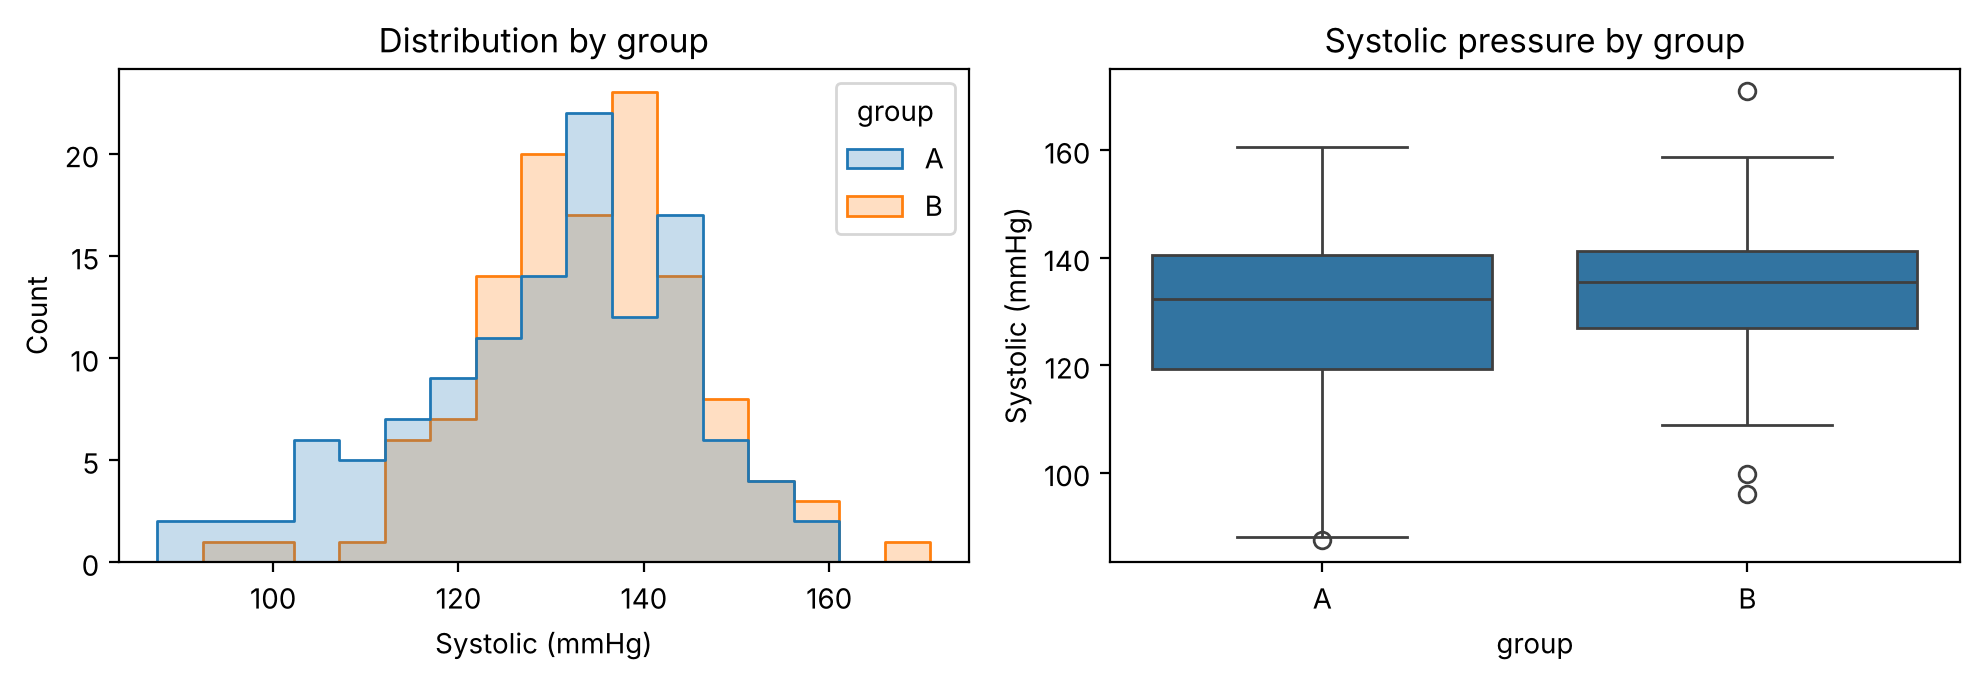

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(patients, x="systolic", hue="group", binwidth=5, element="step", ax=axes[0])
axes[0].set_title("Distribution by group")
sns.boxplot(patients, x="group", y="systolic", ax=axes[1])
axes[1].set_title("Systolic pressure by group")
for ax in axes:
    ax.set_xlabel(ax.get_xlabel().replace("systolic", "Systolic (mmHg)"))
axes[1].set_ylabel("Systolic (mmHg)")
plt.tight_layout(); plt.show()

Group A is lower on average, more spread out, and has a long low tail (roughly 90 to 115 mmHg). Session 9 showed why: group A mixes two recruitment sites. Keep that in mind when we check normality.

### Run the test

Two things to notice in the code:
- **`.dropna()`**: SciPy returns `nan` if any value is missing (`nan_policy="propagate"` is the default). No error, no warning, just `nan`.
- **`equal_var=False`**: this is **Welch's** t-test, which does not assume equal variances. SciPy's default is `equal_var=True` (Student's t-test). Welch's is the safer default: when the variances are equal, it gives almost the same answer; when they aren't, Student's can be badly off.

In [6]:
a = patients.loc[patients["group"] == "A", "systolic"].dropna()
b = patients.loc[patients["group"] == "B", "systolic"].dropna()

res = stats.ttest_ind(a, b, equal_var=False)
ci = res.confidence_interval(confidence_level=0.95)    # CI for mean(a) - mean(b)

print(res)
print(f"mean A = {a.mean():.1f}, mean B = {b.mean():.1f}, difference = {a.mean() - b.mean():.1f} mmHg")
print(f"95% CI for the difference: [{ci.low:.1f}, {ci.high:.1f}]")
print(f"Welch df = {res.df:.1f}")

TtestResult(statistic=np.float64(-2.754700166222451), pvalue=np.float64(0.006350149606331355), df=np.float64(227.39439948907236))
mean A = 129.4, mean B = 134.2, difference = -4.8 mmHg
95% CI for the difference: [-8.3, -1.4]
Welch df = 227.4


**Reading the output.** `statistic` is *t*: the difference in means divided by its standard error. The sign only reflects the order of the arguments (A minus B). `pvalue` is two-sided. `df` is a fraction because Welch's test estimates it.

**Effect size.** Cohen's *d* is the difference in means in units of standard deviation. Rough guide: 0.2 small, 0.5 medium, 0.8 large. These are conventions, not laws; in your field, a "small" *d* might matter a lot.

In [7]:
def cohens_d(x, y):
    # (mean x - mean y) / pooled SD. Same sign convention as ttest_ind(x, y).
    nx, ny = len(x), len(y)
    pooled_var = ((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / (nx + ny - 2)
    return (np.mean(x) - np.mean(y)) / np.sqrt(pooled_var)

print(f"Cohen's d = {cohens_d(a, b):.2f}")

Cohen's d = -0.35


> **Report:** Group A's mean systolic pressure was 4.8 mmHg lower than group B's (129.4 vs. 134.2 mmHg; Welch's *t*(227.4) = −2.75, *p* = 0.006, 95% CI [−8.3, −1.4], *d* = −0.35).

### Check the assumptions

| Assumption | How to check | What it means here |
|---|---|---|
| **Independence** | Study design. No code can check this. | Different patients in A and B ✔ |
| **Roughly normal within each group** (or a large *n*) | Histogram / QQ plot; Shapiro–Wilk as a supplement | Group A is bimodal |
| **Equal variances** (Student's only) | Compare SDs; Levene's test | Irrelevant if you use Welch's |

In [8]:
print("Shapiro-Wilk A:", stats.shapiro(a))
print("Shapiro-Wilk B:", stats.shapiro(b))
print("Levene (A vs B):", stats.levene(a, b))
print(f"SD A = {a.std():.1f}, SD B = {b.std():.1f}")

Shapiro-Wilk A: ShapiroResult(statistic=np.float64(0.9737301862219625), pvalue=np.float64(0.018113980107709295))
Shapiro-Wilk B: ShapiroResult(statistic=np.float64(0.989262670625475), pvalue=np.float64(0.47081187461163776))
Levene (A vs B): LeveneResult(statistic=np.float64(5.929914841601822), pvalue=np.float64(0.015618458542833105))
SD A = 15.1, SD B = 11.9


Shapiro–Wilk flags group A (*p* = 0.018), and Levene's test says the variances differ (*p* = 0.016). How much should we worry?

- **Normality tests are blunt.** With large samples they flag trivial departures; with small samples they miss big ones. The t-test is robust to non-normality at *n* ≈ 120 per group (central limit theorem). Look at the plot and decide; don't let one *p*-value decide for you.
- **But the plot tells us something more important.** Group A is a mixture of two populations. That is a design question (should site be in the model?), not a statistics question.
- **Unequal variances?** We already used Welch's test.

A **rank-based alternative**, Mann–Whitney U, makes no normality assumption. It asks whether values in one group tend to be larger than in the other (it is not a test of medians). Use it as a sensitivity check:

In [9]:
print(stats.mannwhitneyu(a, b, alternative="two-sided"))

MannwhitneyuResult(statistic=np.float64(6082.0), pvalue=np.float64(0.02955261732017892))


Same conclusion (*p* = 0.03). When the parametric and non-parametric tests agree, you can report the t-test with more confidence. When they disagree, figure out why before you choose.

### The paired trap

The course data have no before/after measurements, so here we **simulate** a follow-up visit: 25 patients, each with a baseline pressure, and a drug that lowers it by about 4 mmHg.

In [10]:
baseline = rng.normal(135, 14, 25)                 # people differ a lot from each other...
followup = baseline - rng.normal(4, 4, 25)         # ...but each one drops by about 4

wrong = stats.ttest_ind(baseline, followup)        # treats them as different people
right = stats.ttest_rel(baseline, followup)        # analyzes each patient's change

print(f"independent t-test (wrong): p = {wrong.pvalue:.3f}")
print(f"paired t-test (right):      p = {right.pvalue:.2e}")

diff = baseline - followup
print(f"one-sample t-test on the differences: p = {stats.ttest_1samp(diff, 0).pvalue:.2e}")
print(f"mean drop = {diff.mean():.1f} mmHg, d_z = {diff.mean() / diff.std(ddof=1):.2f}")

independent t-test (wrong): p = 0.322
paired t-test (right):      p = 6.57e-05
one-sample t-test on the differences: p = 6.57e-05
mean drop = 4.0 mmHg, d_z = 0.96


The independent test buries a real 4 mmHg drop under the 14 mmHg spread *between* patients. The paired test removes that spread by looking at each patient's own change. Note that a paired t-test **is** a one-sample t-test on the differences; the *p*-values are identical.

This is one of the most common errors in AI-generated analysis code. Paired data need `ttest_rel`, and the two arrays must be in the same subject order.

## 3. Three or more groups: one-way ANOVA

**Question:** Does body mass differ among the three penguin species?
Continuous outcome, three independent groups → **one-way ANOVA.**

Why not three t-tests? Each test has a 5% false-positive rate, so three tests give roughly a 14% chance of at least one false positive (1 − 0.95³). ANOVA asks one question first: *is there any difference among the means?*

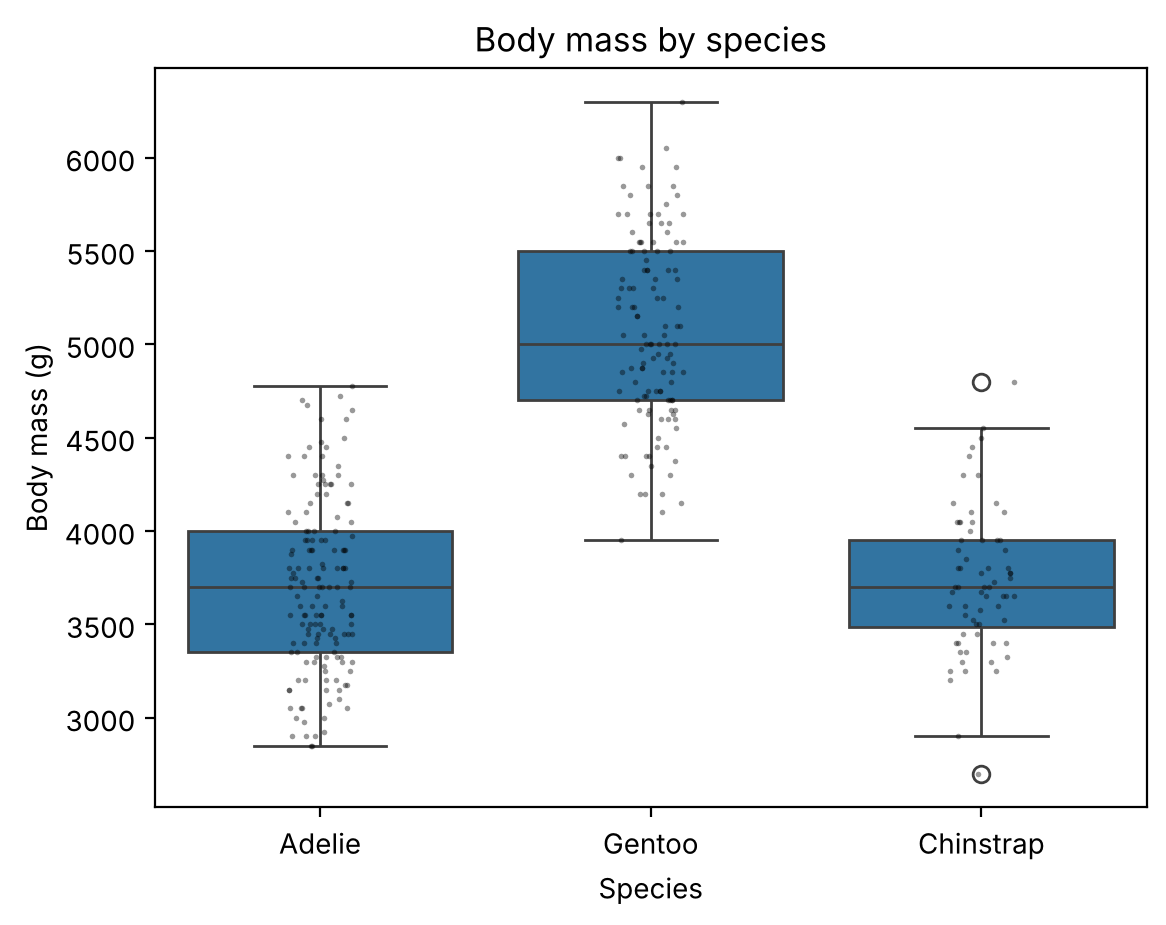

,count,mean,std
species,,,
Adelie,151,3700.662,458.566
Chinstrap,68,3733.088,384.335
Gentoo,123,5076.016,504.116


In [11]:
sns.boxplot(penguins, x="species", y="body_mass_g")
sns.stripplot(penguins, x="species", y="body_mass_g", color="black", size=2, alpha=0.4)
plt.ylabel("Body mass (g)"); plt.xlabel("Species"); plt.title("Body mass by species")
plt.show()

penguins.groupby("species")["body_mass_g"].agg(["count", "mean", "std"])

### The silent `nan`

Two penguins have no measurements. Watch what happens if we forget:

In [12]:
groups_with_nan = [d["body_mass_g"] for _, d in penguins.groupby("species")]
print(stats.f_oneway(*groups_with_nan))              # nan, nan: no error, no warning

groups = [d["body_mass_g"].dropna() for _, d in penguins.groupby("species")]
print(stats.f_oneway(*groups))

F_onewayResult(statistic=np.float64(nan), pvalue=np.float64(nan))
F_onewayResult(statistic=np.float64(343.626275205481), pvalue=np.float64(2.8923681333772844e-82))


`*groups` unpacks the list, so `f_oneway(*groups)` is the same as `f_oneway(adelie, chinstrap, gentoo)`.

### The formula interface: ANOVA is a linear model

`statsmodels` fits ANOVA as a regression with a categorical predictor. This gives you the full ANOVA table, from which we get the effect size **η²** (eta squared): the share of the variation in body mass explained by species. The formula `"body_mass_g ~ species"` reads "body mass modeled by species," the same syntax as R. Rows with missing values are dropped automatically.

In [13]:
model = smf.ols("body_mass_g ~ species", data=penguins).fit()
aov = sm.stats.anova_lm(model, typ=2)
eta_sq = aov.loc["species", "sum_sq"] / aov["sum_sq"].sum()

print(aov)
print(f"\neta squared = {eta_sq:.2f}")

             sum_sq     df        F     PR(>F)
species   1.469e+08    2.0  343.626  2.892e-82
Residual  7.244e+07  339.0      NaN        NaN

eta squared = 0.67


**Reading the table.** `sum_sq` splits the total variation into *between species* and *residual* (within species). `F` is the between-group variance divided by the within-group variance. `PR(>F)` is the *p*-value. Report both degrees of freedom: *F*(2, 339) = 343.6, *p* < 0.001, η² = 0.67. Species explains about two-thirds of the variation in body mass.

### Assumptions, and what to do when they wobble

Same as the t-test: independent observations, roughly normal residuals within groups, and **similar variances**. Here the SDs range from 384 to 504 g.

In [14]:
print("Levene:", stats.levene(*groups))
welch = anova_oneway(groups, use_var="unequal")     # Welch's ANOVA: no equal-variance assumption
print(f"Welch ANOVA: F = {welch.statistic:.1f}, df = (2, {welch.df_denom:.1f}), p = {welch.pvalue:.1e}")
print("Kruskal-Wallis:", stats.kruskal(*groups))     # rank-based alternative

Levene: LeveneResult(statistic=np.float64(5.12025099751946), pvalue=np.float64(0.006445082805324017))
Welch ANOVA: F = 317.6, df = (2, 189.5), p = 3.1e-61
Kruskal-Wallis: KruskalResult(statistic=np.float64(217.59924143680436), pvalue=np.float64(5.609512095829062e-48))


Levene's test flags the variances (*p* = 0.006), but Welch's ANOVA and Kruskal–Wallis reach the same conclusion. The effect is far too large for these assumptions to change it. Assumptions matter most when results are borderline.

### Post-hoc: which species differ?

A significant ANOVA says *some* means differ, not *which*. Tukey's HSD compares every pair while holding the family-wise error rate at 5%:

In [15]:
mass = penguins.dropna(subset=["body_mass_g"])
print(pairwise_tukeyhsd(mass["body_mass_g"], mass["species"], alpha=0.05))

     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2  meandiff p-adj    lower     upper   reject
--------------------------------------------------------------
   Adelie Chinstrap   32.426 0.8807 -126.5002  191.3522  False
   Adelie    Gentoo 1375.354    0.0 1243.1786 1507.5294   True
Chinstrap    Gentoo 1342.928    0.0  1178.481  1507.375   True
--------------------------------------------------------------


Gentoo penguins are about 1,350 g heavier than both other species; Adelie and Chinstrap don't differ (*p* = 0.88, and the CI of −127 to 191 g includes 0). `meandiff` is `group2 − group1`.

**Another approach:** run pairwise tests yourself and correct the *p*-values with `multipletests`. Holm's method is a good default; Bonferroni is more conservative.

In [16]:
pairs = [("Adelie", "Chinstrap"), ("Adelie", "Gentoo"), ("Chinstrap", "Gentoo")]
raw_p = [stats.ttest_ind(mass.loc[mass.species == g1, "body_mass_g"],
                         mass.loc[mass.species == g2, "body_mass_g"],
                         equal_var=False).pvalue for g1, g2 in pairs]
reject, adj_p, _, _ = multipletests(raw_p, method="holm")
pd.DataFrame({"pair": [f"{g1} vs {g2}" for g1, g2 in pairs], "raw p": raw_p,
              "Holm-adjusted p": adj_p, "reject at 0.05": reject})

,pair,raw p,Holm-adjusted p,reject at 0.05
0,Adelie vs Chinstrap,5.879e-01,5.879e-01,False
1,Adelie vs Gentoo,7.710e-65,2.313e-64,True
2,Chinstrap vs Gentoo,3.414e-48,6.828e-48,True


## 4. Two categorical variables: chi-square test of independence

**Question:** Is sex associated with species? (Did the researchers sample males and females in the same proportions across species?)
Two categorical variables → **chi-square test** on a table of **counts**.

In [17]:
table = pd.crosstab(penguins["species"], penguins["sex"])   # rows with missing sex are dropped
table

sex,female,male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


In [18]:
chi = stats.chi2_contingency(table)
print(f"chi2 = {chi.statistic:.3f}, df = {chi.dof}, p = {chi.pvalue:.3f}")
pd.DataFrame(chi.expected_freq, index=table.index, columns=table.columns).round(1)

chi2 = 0.049, df = 2, p = 0.976


sex,female,male
species,,
Adelie,72.3,73.7
Chinstrap,33.7,34.3
Gentoo,59.0,60.0


**Reading the output.** The test compares observed counts with the counts **expected** if the two variables were unrelated (row total × column total ÷ grand total). The expected table above is almost identical to the observed one, so χ² is tiny.

> **Report:** Sex ratios did not differ by species (χ²(2) = 0.05, *p* = 0.98, *n* = 333).

That is **not** evidence that the proportions are identical; "no evidence of a difference" ≠ "evidence of no difference." A confidence interval or an equivalence test would be needed to claim that.

**Assumptions:** independent observations (each penguin counted once), **counts** (not percentages), and expected counts of at least about 5 per cell. If a 2×2 table has small expected counts, use `stats.fisher_exact`. For 2×2 tables, `chi2_contingency` applies Yates' continuity correction by default (`correction=True`), as does R's `chisq.test()`.

**Effect size: Cramér's V** runs from 0 (no association) to 1 (perfect association). Compare a null result with a strong one, species by island:

In [19]:
from scipy.stats.contingency import association

island = pd.crosstab(penguins["species"], penguins["island"])
display(island)
chi_i = stats.chi2_contingency(island)
print(f"species x island: chi2 = {chi_i.statistic:.1f}, p = {chi_i.pvalue:.1e}, "
      f"Cramer's V = {association(island, method='cramer'):.2f}")
print(f"species x sex:    Cramer's V = {association(table, method='cramer'):.2f}")

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


species x island: chi2 = 299.6, p = 1.4e-63, Cramer's V = 0.66
species x sex:    Cramer's V = 0.01


Species and island are strongly associated (V = 0.66): Gentoo were only found on Biscoe and Chinstrap only on Dream. The test isn't wrong, but ask whether it answers an interesting question. Here the "association" is just where each species lives.

## 5. Linear regression: reading the summary table

**Question:** How much heavier is a penguin for each extra millimeter of flipper?
Continuous outcome, continuous predictor → **linear regression.**

In [20]:
fit = smf.ols("body_mass_g ~ flipper_length_mm", data=penguins).fit()
print(fit.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
No. Observations:                 342   F-statistic:                     1071.
Covariance Type:            nonrobust   Prob (F-statistic):          4.37e-107
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.815    -18.903      0.000   -6382.358   -5179.305
flipper_length_mm    49.6856      1.518     32.722      0.000      46.699      52.672

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.89e+03. This might indicate that there are
strong multicollinearity or other numerical problems.


**How to read this table** (and R's `summary(lm(...))`, which has the same pieces):

| Piece | Value | Meaning |
|---|---|---|
| `coef` for `flipper_length_mm` | 49.7 | Each extra mm of flipper goes with ~50 g more body mass, on average |
| `Intercept` | −5781 | Predicted mass at flipper length 0. Not meaningful here; it just anchors the line |
| `std err` | 1.5 | Uncertainty in the slope |
| `t`, `P>|t|` | 32.7, 0.000 | Test of "slope = 0." `0.000` means *p* < 0.0005, **not** zero |
| `[0.025  0.975]` | 46.7 to 52.7 | 95% CI for the slope: the effect size with its uncertainty |
| `R-squared` | 0.76 | Flipper length explains 76% of the variation in body mass |
| `No. Observations` | 342 | Two penguins with missing values were dropped. Always check this number. |

The note about a large condition number appears because flipper lengths are around 200 while the intercept sits at 0; it is not a problem with a single predictor.

The same numbers are available individually, which is how you put them in a report:

In [21]:
print(fit.params.round(2))
print(fit.conf_int().round(2))
print(f"R2 = {fit.rsquared:.3f}, n = {int(fit.nobs)}")

Intercept           -5780.83
flipper_length_mm      49.69
dtype: float64
                         0        1
Intercept         -6382.36 -5179.30
flipper_length_mm    46.70    52.67
R2 = 0.759, n = 342


### Assumptions: check the residuals

**L**inearity, **I**ndependence, **N**ormality of residuals, **E**qual variance of residuals (LINE). Session 10 covered these plots; here's the quick version. We want a shapeless cloud around 0 (left) and points close to the line (right).

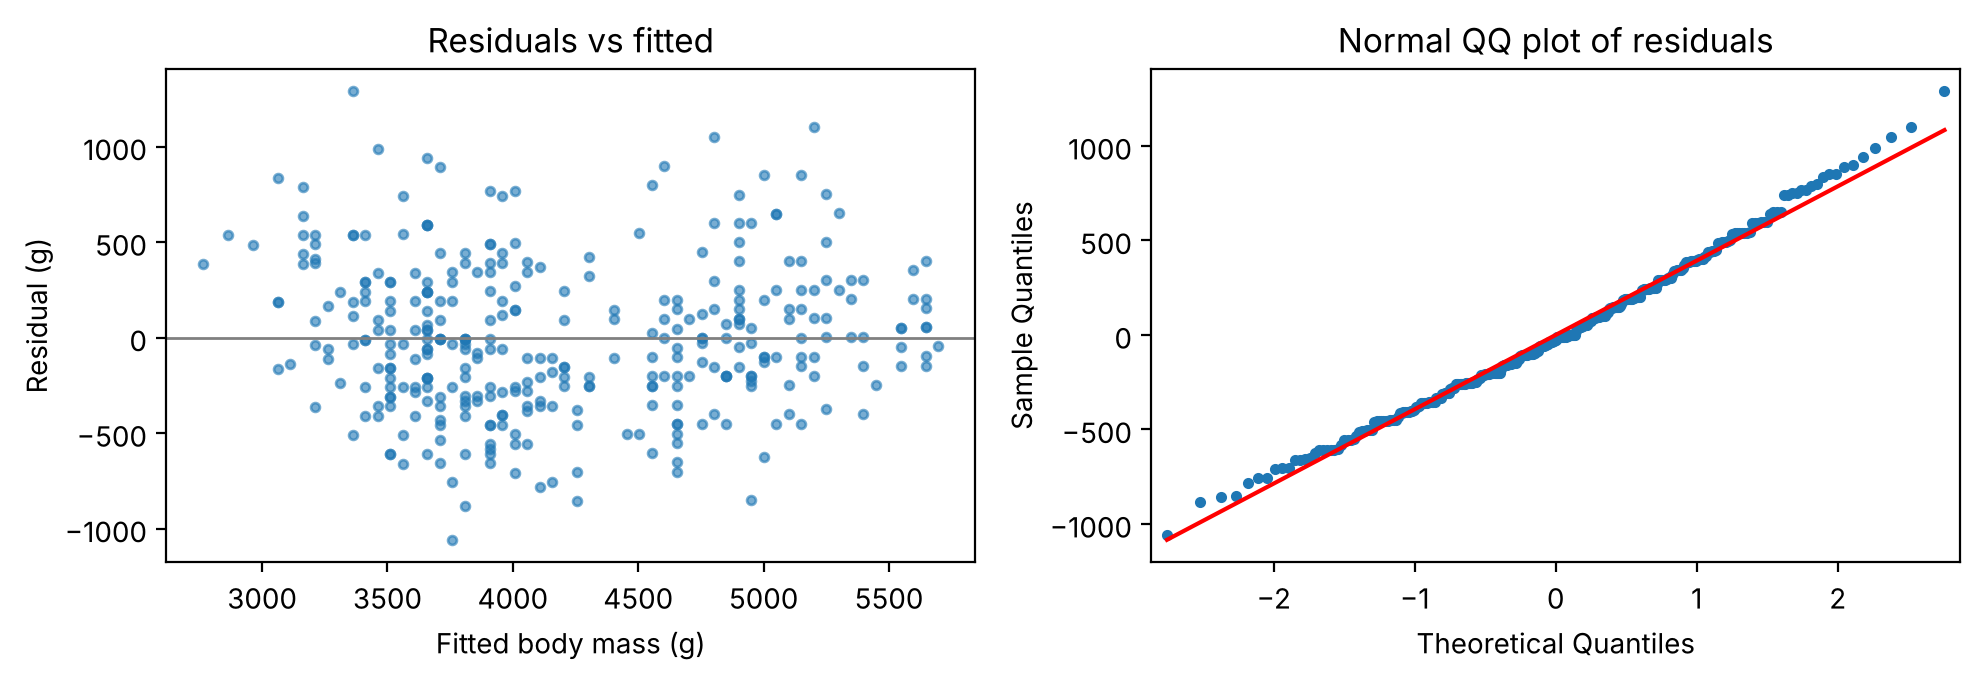

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(fit.fittedvalues, fit.resid, s=10, alpha=0.6)
axes[0].axhline(0, color="gray", lw=1)
axes[0].set(xlabel="Fitted body mass (g)", ylabel="Residual (g)", title="Residuals vs fitted")
sm.qqplot(fit.resid, line="s", ax=axes[1], markersize=3)
axes[1].set_title("Normal QQ plot of residuals")
plt.tight_layout(); plt.show()

Reasonable. Note that normality applies to the **residuals**, not to the raw outcome or predictor.

### Adding a variable changes the meaning of a coefficient

Remember Simpson's paradox from Session 9: across all penguins, longer bills go with *shallower* bills; within each species, the opposite. Regression shows the same thing:

In [23]:
m1 = smf.ols("bill_depth_mm ~ bill_length_mm", data=penguins).fit()
m2 = smf.ols("bill_depth_mm ~ bill_length_mm + species", data=penguins).fit()

print(f"without species: slope = {m1.params['bill_length_mm']:+.3f} mm/mm, p = {m1.pvalues['bill_length_mm']:.1e}")
print(f"with species:    slope = {m2.params['bill_length_mm']:+.3f} mm/mm, p = {m2.pvalues['bill_length_mm']:.1e}")
print(m2.params.round(2))

without species: slope = -0.085 mm/mm, p = 1.1e-05
with species:    slope = +0.200 mm/mm, p = 8.7e-26
Intercept               10.59
species[T.Chinstrap]    -1.93
species[T.Gentoo]       -5.11
bill_length_mm           0.20
dtype: float64


Both slopes are "highly significant" and they point in **opposite directions**. A coefficient means "the effect of *x*, holding the other variables in the model constant." Which variables belong in the model is a scientific decision, not a statistical one.

`species[T.Chinstrap]` and `species[T.Gentoo]` are **dummy variables**: each one is that species' difference from the **reference level**, Adelie (first alphabetically). R uses the same convention.

## 6. Reading output in Python and R

The same test produces differently named output in each language. Here is where to find the numbers you need to report:

| Test | Python | R | Statistic | df | *p* | CI | Effect size |
|---|---|---|---|---|---|---|---|
| Welch t-test | `stats.ttest_ind(a, b, equal_var=False)` | `t.test(a, b)` (Welch is R's default) | `.statistic` / `t =` | `.df` / `df =` | `.pvalue` / `p-value =` | `.confidence_interval()` / `95 percent confidence interval` | compute *d* (`effectsize::cohens_d`) |
| Paired t-test | `stats.ttest_rel(x, y)` | `t.test(x, y, paired = TRUE)` | same | same | same | same | *d*<sub>z</sub> |
| One-way ANOVA | `smf.ols(...)` + `anova_lm` | `aov()` + `summary()` | `F` / `F value` | 2 rows of `df` / `Df` | `PR(>F)` / `Pr(>F)` | from post-hoc | η² |
| Tukey HSD | `pairwise_tukeyhsd` | `TukeyHSD(aov(...))` | — | — | `p-adj` | `lower`, `upper` / `lwr`, `upr` | mean difference |
| Chi-square | `stats.chi2_contingency(table)` | `chisq.test(table)` | `.statistic` / `X-squared` | `.dof` / `df` | `.pvalue` | — | Cramér's V |
| Regression | `smf.ols(...).fit().summary()` | `summary(lm(...))` | `t` / `t value` | `Df Residuals` / `degrees of freedom` | `P>|t|` / `Pr(>|t|)` | `[0.025 0.975]` / `confint()` | coefficient, *R*² |

Two differences that catch people switching languages:
- **R's `t.test()` defaults to Welch's; SciPy's `ttest_ind()` defaults to Student's.** Same function name in your head, different answers.
- **R prints `< 2e-16`, statsmodels prints `0.000`.** Neither means *p* = 0. Report "*p* < 0.001."

## 7. Spot the bug

Each cell below is the kind of code an AI assistant writes. Each one runs without an error. What's wrong, and how would you fix it? (Solutions are at the bottom.)

**Bug 1.** "Compare systolic pressure between women and men."

In [24]:
f = raw.loc[raw["sex"] == "F", "systolic"].dropna()
m = raw.loc[raw["sex"] == "M", "systolic"].dropna()
print(len(f), len(m), stats.ttest_ind(f, m, equal_var=False).pvalue)

109 114 0.31801650460008407


**Bug 2.** "Missing values were breaking the test, so I filled them in."

In [25]:
filled = penguins["body_mass_g"].fillna(0)
print(stats.f_oneway(*[filled[penguins["species"] == s] for s in penguins["species"].unique()]))

F_onewayResult(statistic=np.float64(218.16241172935668), pvalue=np.float64(9.702621236667115e-62))


**Bug 3.** "Was Adelie sampling spread evenly across years on each island? Here's the chi-square test on the percentages."

In [26]:
adelie = penguins[penguins["species"] == "Adelie"]
pct = pd.crosstab(adelie["island"], adelie["year"], normalize="index") * 100
print(pct.round(1))
print(stats.chi2_contingency(pct).pvalue)

year       2007  2008  2009
island                     
Biscoe     22.7  40.9  36.4
Dream      35.7  28.6  35.7
Torgersen  38.5  30.8  30.8
0.111200809783949


**Bug 4.** "Species differ in flipper length: I ran a t-test for each pair, and all three are significant at *p* < 0.05."

```python
for g1, g2 in pairs:
    p = stats.ttest_ind(mass.loc[mass.species == g1, "flipper_length_mm"],
                        mass.loc[mass.species == g2, "flipper_length_mm"]).pvalue
    print(g1, g2, p < 0.05)
```

**Bug 5.** "The chi-square test gave *p* = 0.98, which proves that sex and species are independent."

<details>
<summary><b>Solutions</b> (click to expand)</summary>

1. **Silent data loss, the Session 1 bug again.** `raw["sex"]` still contains `"f"` and `"m"`, so those patients are dropped. The buggy code compares 109 women with 114 men; the cleaned `patients` table has 118 and 123. Use the cleaned table, and always print the group sizes.
2. **`fillna(0)` invents two penguins weighing 0 g.** This drags down two group means and inflates the variance (*F* falls from 343.6 to 218.2). Drop missing values for the test (`.dropna()`) and report how many you dropped. Never fill a measurement with 0 to make a test run.
3. **Chi-square needs counts.** Percentages hide the sample size: each row sums to 100 whether the island had 10 penguins or 10,000. Here each island has 44–56 Adelie penguins, so the percentages roughly double the apparent sample size, and *p* drops from 0.47 (counts, correct) to 0.11. With other tables it can cross 0.05. Pass the table of counts (`pd.crosstab` without `normalize`).
4. **Two issues.** Three uncorrected tests inflate the false-positive rate (use ANOVA + Tukey or Holm-adjusted *p*-values), and `ttest_ind` defaults to Student's (equal variances), not Welch's. Also, `print(p < 0.05)` throws away the effect size and CI. (The conclusion happens to survive correction here; the method still needs fixing.)
5. **A large *p*-value is not proof of no effect.** It means the data are compatible with no association. They may also be compatible with a small association. Report the effect size (Cramér's V = 0.01) and the sample size.

</details>

## 8. Reporting templates

- **Welch's t-test:** *t*(df) = X.XX, *p* = .XXX, mean difference = M [95% CI L, U], *d* = X.XX
- **Paired t-test:** *t*(n−1) = X.XX, *p* = .XXX, mean change = M [95% CI L, U], *d*<sub>z</sub> = X.XX
- **One-way ANOVA:** *F*(k−1, N−k) = X.XX, *p* = .XXX, η² = X.XX; then post-hoc differences with CIs
- **Chi-square:** χ²(df) = X.XX, *p* = .XXX, *n* = N, Cramér's V = X.XX
- **Regression:** *b* = X.XX [95% CI L, U], *t*(df) = X.XX, *p* = .XXX; *R*² = X.XX, *n* = N

Report exact *p*-values to two or three decimals (*p* = 0.006), and *p* < 0.001 for anything smaller. Always report *n* after missing values are dropped.

## For your project

Pick one research question from your dataset and write down, *before* running any code:
1. The outcome variable and its type
2. What it's compared across, and whether the observations are independent or paired
3. The test you'll use and the assumption you're most worried about
4. The three numbers you'll report

Then run it, plot the data, and check that the *n* in the output matches what you expect.